# SiteScore — 03 Validation

We test the models from notebook 02 using the data prepared in notebook 01.
On the held-out Indianapolis sample, AUC is **0.687**, compared with **0.671** for the concept-only model.
The two B3 versions perform similarly. The model offers modest ranking value; it does not predict closure within a future year.

## Step 0 — Settings

Run notebook 01 first to create `outputs/restaurants_clean.csv`. This notebook refits the specifications from 02.

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, RocCurveDisplay,
                             PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.neighbors import BallTree
from IPython.display import display

SEED = 42
N_SPLITS = 5
N_BOOTSTRAP = 1000
BOOTSTRAP_GRID_KM = 2.0
GREEN, RUST, GREY = '#1f4e3d', '#b5543c', '#8a8a8a'
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 10})

candidates = [Path('outputs/restaurants_clean.csv'),
              Path('notebooks/outputs/restaurants_clean.csv')]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Run notebook 01 first, then open 03 from the repository root or notebooks folder.')
OUTPUT_DIR = DATA_PATH.parent
PROJECT_ROOT = OUTPUT_DIR.parent.parent if OUTPUT_DIR.parent.name == 'notebooks' else Path.cwd()
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Step 1 — Split the data

We hold out Indianapolis (4,150 restaurants), the metro closest to 4,000 restaurants after excluding the largest metro. The other 48,118 restaurants are used for training.

We use B3 without metro dummies because an unseen city has no fitted city coefficient. Five-fold cross-validation keeps whole metros together. Model choice and the second classification cutoff use training folds only.

**Assumptions.** Price, cuisine, location and chain information come from the current catalogue, rather than historical opening dates. No closure labels or open-neighbour counts enter the predictors. Notebook 02 already explored all metros, so these tests remain exploratory.

In [2]:
df = pd.read_csv(DATA_PATH, dtype={'price_tier': str})
assert len(df) == 52268 and df['business_id'].is_unique
assert df['closed'].isin([0, 1]).all() and int(df['closed'].sum()) == 17281
required = ['price_tier', 'cuisine_group', 'is_chain', 'log_n_rest_500m',
            'same_cuisine_share_500m', 'abs_price_gap', 'price_gap_missing', 'metro']
assert not df[required + ['closed', 'latitude', 'longitude']].isna().any().any()
for radius in [250, 500, 1000]:
    assert (df[f'n_rest_{radius}m'] >= df[f'n_same_cuisine_{radius}m']).all()
    assert (df[f'n_same_cuisine_{radius}m'] >= 0).all()
    expected_share = np.where(df[f'n_rest_{radius}m'] > 0,
                              df[f'n_same_cuisine_{radius}m'] / df[f'n_rest_{radius}m'].clip(lower=1), 0)
    assert np.allclose(df[f'same_cuisine_share_{radius}m'], expected_share)
    df[f'same_cuisine_share_{radius}m_10pp'] = 10 * df[f'same_cuisine_share_{radius}m']
    df[f'has_same_cuisine_{radius}m'] = (df[f'n_same_cuisine_{radius}m'] > 0).astype(int)
assert (df['is_chain_3'] >= df['is_chain_5']).all()
assert (df['is_chain_5'] >= df['is_chain_10']).all()
assert np.array_equal(df['is_chain'], df['is_chain_5'])
df['same_cuisine_share_10pp'] = 10 * df['same_cuisine_share_500m']
df['has_same_cuisine_nbr'] = df['has_same_cuisine_500m']

metro_counts = df['metro'].value_counts()
eligible_metros = metro_counts.drop(metro_counts.idxmax())
HOLDOUT_METRO = (eligible_metros - 4000).abs().sort_values(kind='stable').index[0]
train = df.loc[df['metro'] != HOLDOUT_METRO].copy().reset_index(drop=True)
test = df.loc[df['metro'] == HOLDOUT_METRO].copy().reset_index(drop=True)
assert set(train['business_id']).isdisjoint(test['business_id'])
assert set(train['metro']).isdisjoint(test['metro'])
split_table = pd.DataFrame({'Restaurants': [len(train), len(test)],
                            'Closed': [train.closed.sum(), test.closed.sum()],
                            'Closed share': [train.closed.mean(), test.closed.mean()]},
                           index=['Training metros', f'Test: {HOLDOUT_METRO}'])
display(split_table.style.format({'Restaurants': '{:,}', 'Closed': '{:,}', 'Closed share': '{:.1%}'}))
print('Holdout selected from restaurant counts only:', HOLDOUT_METRO)

,Restaurants,Closed,Closed share
Training metros,"48,118","15,967",33.2%
Test: Indianapolis,"4,150","1,314",31.7%


Holdout selected from restaurant counts only: Indianapolis


## Step 2 — Models and metrics

Compare the training-rate and chain-only baselines, B1 concept, B3 share and B3 with a yes/no same-cuisine-neighbour indicator.

AUC measures ranking (0.5 is the baseline); AP summarizes precision and recall across cutoffs. Probability MSE measures probability error (lower is better). Classification metrics use the stated cutoff.

In [3]:
PRICE = "C(price_tier, Treatment('1'))"
CUISINE = "C(cuisine_group, Treatment('Burgers & Fast Food'))"
BASELINE = 'Training-rate baseline'
CHAIN = 'Chain-only baseline'
CONCEPT = 'B1 concept'
MAIN = 'B3 share'
ALTERNATIVE = 'B3 any neighbour'
MODEL_NAMES = [BASELINE, CHAIN, CONCEPT, MAIN, ALTERNATIVE]

def formula_for(model_name, radius=500, chain_column='is_chain'):
    concept = f'{PRICE} + {CUISINE} + {chain_column}'
    if model_name == CHAIN:
        return f'closed ~ {chain_column}'
    if model_name == CONCEPT:
        return 'closed ~ ' + concept
    same = ('same_cuisine_share_10pp' if radius == 500 else f'same_cuisine_share_{radius}m_10pp')
    if model_name == ALTERNATIVE:
        same = 'has_same_cuisine_nbr' if radius == 500 else f'has_same_cuisine_{radius}m'
    gap = 'abs_price_gap' if radius == 500 else f'abs_price_gap_{radius}m'
    missing = 'price_gap_missing' if radius == 500 else f'price_gap_missing_{radius}m'
    return f'closed ~ {concept} + log_n_rest_{radius}m + {same} + {gap} + {missing}'

FORMULAS = {name: formula_for(name) for name in MODEL_NAMES if name != BASELINE}
for formula in FORMULAS.values():
    assert all(x not in formula.split('~', 1)[1] for x in ['metro', 'n_open_', 'is_open', 'closed', 'stars', 'review'])
formula_file = OUTPUT_DIR / 'model_formula.txt'
if formula_file.exists():
    original = next(line.split(': ', 1)[1] for line in formula_file.read_text().splitlines()
                    if line.startswith('B3 + Price position: '))
    assert original.split() == FORMULAS[MAIN].split(), 'B3 changed in notebook 02; review the validation specification.'
display(pd.DataFrame({'Formula': FORMULAS}).rename_axis('Model'))

def fit_predict(model_name, fit_data, new_data, radius=500, chain_column='is_chain'):
    if model_name == BASELINE:
        return None, np.full(len(new_data), fit_data.closed.mean())
    for col in ['price_tier', 'cuisine_group'] if model_name != CHAIN else []:
        unseen = set(new_data[col]) - set(fit_data[col])
        if unseen:
            raise ValueError(f'Unseen {col}: {unseen}; do not silently invent a category effect.')
    result = smf.glm(formula_for(model_name, radius, chain_column), data=fit_data,
                     family=sm.families.Binomial(), missing='raise').fit()
    assert result.converged
    probabilities = np.asarray(result.predict(new_data), dtype=float)
    assert len(probabilities) == len(new_data) and np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    return result, probabilities

def metrics(y, probabilities, threshold=0.5):
    y, p = np.asarray(y, int), np.asarray(probabilities, float)
    predicted = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    two_classes = np.unique(y).size == 2
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else np.nan
    return {'n': len(y), 'AUC': roc_auc_score(y, p) if two_classes else np.nan,
            'AP': average_precision_score(y, p) if two_classes else np.nan,
            'Probability MSE': np.mean((p - y)**2), 'Accuracy': (tp + tn) / len(y),
            'Precision': precision, 'Recall': recall,
            'F1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

def show_metrics(table):
    cols = ['AUC', 'AP', 'Probability MSE', 'Accuracy', 'Precision', 'Recall', 'F1']
    return table[cols].style.format({**{c: '{:.3f}' for c in cols[:3]},
                                   **{c: '{:.1%}' for c in cols[3:]}})

,Formula
Model,
Chain-only baseline,closed ~ is_chain
B1 concept,"closed ~ C(price_tier, Treatment('1')) + C(cui..."
B3 share,"closed ~ C(price_tier, Treatment('1')) + C(cui..."
B3 any neighbour,"closed ~ C(price_tier, Treatment('1')) + C(cui..."


## Step 3 — Cross-validation

Refit each model within each training fold. Select the B3 version with the higher mean AUC, then choose an F1 cutoff from its out-of-fold training predictions. This cutoff balances precision and recall; it does not account for business costs.

In [4]:
folds = list(GroupKFold(n_splits=N_SPLITS).split(train, groups=train['metro']))
oof = {name: np.full(len(train), np.nan) for name in MODEL_NAMES}
fold_rows, fold_membership = [], []
for fold, (fit_idx, val_idx) in enumerate(folds, 1):
    fit_data, val_data = train.iloc[fit_idx], train.iloc[val_idx]
    assert set(fit_data.metro).isdisjoint(val_data.metro)
    fold_membership.append({'Fold': fold, 'Training n': len(fit_data), 'Validation n': len(val_data),
                            'Validation metros': ', '.join(sorted(val_data.metro.unique()))})
    for name in MODEL_NAMES:
        _, probabilities = fit_predict(name, fit_data, val_data)
        oof[name][val_idx] = probabilities
        fold_rows.append({'Model': name, 'Fold': fold, **metrics(val_data.closed, probabilities)})
assert all(np.isfinite(p).all() for p in oof.values())
cv_folds = pd.DataFrame(fold_rows)
cv_summary = cv_folds.groupby('Model', sort=False).agg(
    AUC_mean=('AUC', 'mean'), AUC_SD=('AUC', 'std'), AP_mean=('AP', 'mean'),
    Probability_MSE_mean=('Probability MSE', 'mean'), F1_mean=('F1', 'mean'))
display(pd.DataFrame(fold_membership))
display(cv_summary.style.format('{:.4f}'))

SELECTED_MODEL = cv_summary.loc[[MAIN, ALTERNATIVE], 'AUC_mean'].idxmax()
precision_oof, recall_oof, thresholds_oof = precision_recall_curve(train.closed, oof[SELECTED_MODEL])
f1_oof = 2 * precision_oof[:-1] * recall_oof[:-1] / np.maximum(precision_oof[:-1] + recall_oof[:-1], 1e-15)
best = np.flatnonzero(np.isclose(f1_oof, f1_oof.max(), rtol=0, atol=1e-12))[-1]
TRAINING_THRESHOLD = float(thresholds_oof[best])
print('Training-side choice:', SELECTED_MODEL)
print(f'Training-side F1 threshold: {TRAINING_THRESHOLD:.3f}; default threshold remains 0.500.')

,Fold,Training n,Validation n,Validation metros
0,1,31174,16944,Philadelphia
1,2,39386,8732,Tampa
2,3,41213,6905,"Reno, St. Louis"
3,4,40195,7923,"Edmonton, Nashville, Santa Barbara"
4,5,40504,7614,"Boise, New Orleans, Tucson"


,AUC_mean,AUC_SD,AP_mean,Probability_MSE_mean,F1_mean
Model,,,,,
Training-rate baseline,0.5000,0.0000,0.3306,0.2214,0.0000
Chain-only baseline,0.5909,0.0244,0.3778,0.2128,0.0000
B1 concept,0.6510,0.0178,0.4478,0.2069,0.1917
B3 share,0.6712,0.0139,0.4724,0.2045,0.2452
B3 any neighbour,0.6724,0.0146,0.4733,0.2042,0.2421


Training-side choice: B3 any neighbour
Training-side F1 threshold: 0.293; default threshold remains 0.500.


## Step 4 — Held-out results

Fit the models on the training metros and evaluate Indianapolis. Neither the model choice nor the cutoff is changed using these results.

The selected B3 model has AUC **0.687**, versus **0.671** for B1. The share version is nearly tied at **0.6866**. The two versions are effectively tied in cross-validation too (mean AUC 0.6724 vs 0.6712), so the choice is not a performance claim: we use the yes/no version because it is easier to explain and fit better in notebook 02 (Step 6b).

In [5]:
fitted_models, test_predictions, rows = {}, {}, []
for name in MODEL_NAMES:
    fitted_models[name], probabilities = fit_predict(name, train, test)
    test_predictions[name] = probabilities
    rows.append({'Model': name, **metrics(test.closed, probabilities)})
test_results = pd.DataFrame(rows).set_index('Model')
display(show_metrics(test_results))
print(f'Test metro: {HOLDOUT_METRO}; n = {len(test):,}; closed share = {test.closed.mean():.1%}.')

,AUC,AP,Probability MSE,Accuracy,Precision,Recall,F1
Model,,,,,,,
Training-rate baseline,0.500,0.317,0.217,68.3%,0.0%,0.0%,0.0%
Chain-only baseline,0.618,0.381,0.205,68.3%,0.0%,0.0%,0.0%
B1 concept,0.671,0.454,0.200,69.1%,56.9%,10.4%,17.5%
B3 share,0.687,0.487,0.197,69.7%,59.3%,13.5%,22.1%
B3 any neighbour,0.687,0.485,0.197,69.6%,59.0%,13.2%,21.6%


Test metro: Indianapolis; n = 4,150; closed share = 31.7%.


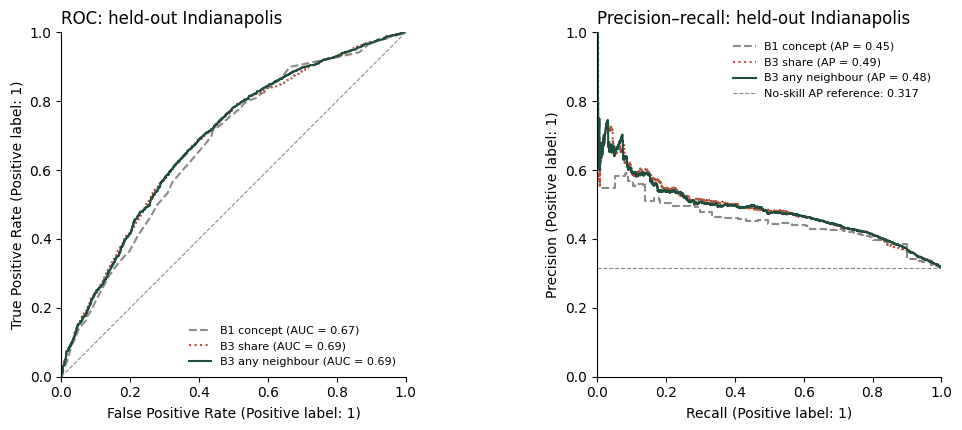

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
curves = [(CONCEPT, GREY, '--'), (MAIN, RUST, ':'), (ALTERNATIVE, GREEN, '-')]
for name, color, style in curves:
    roc_display = RocCurveDisplay.from_predictions(test.closed, test_predictions[name], name=name, ax=axes[0])
    pr_display = PrecisionRecallDisplay.from_predictions(test.closed, test_predictions[name], name=name, ax=axes[1])
    roc_display.line_.set(color=color, linestyle=style)
    pr_display.line_.set(color=color, linestyle=style)
axes[0].plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=0.8)
axes[1].axhline(test.closed.mean(), color=GREY, linestyle='--', linewidth=0.8,
               label=f'No-skill AP reference: {test.closed.mean():.3f}')
axes[0].set_title(f'ROC: held-out {HOLDOUT_METRO}', loc='left')
axes[1].set_title(f'Precision–recall: held-out {HOLDOUT_METRO}', loc='left')
for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'validation_roc_pr.png', dpi=180, bbox_inches='tight')
plt.show()

### Classification cutoffs

Rows show actual status; columns show predicted status. At 0.5, recall is **13.2%**. The training-selected cutoff of **0.293** raises recall to **70.8%**, with **43.9% precision**. False alarms increase from **121 to 1,189**.

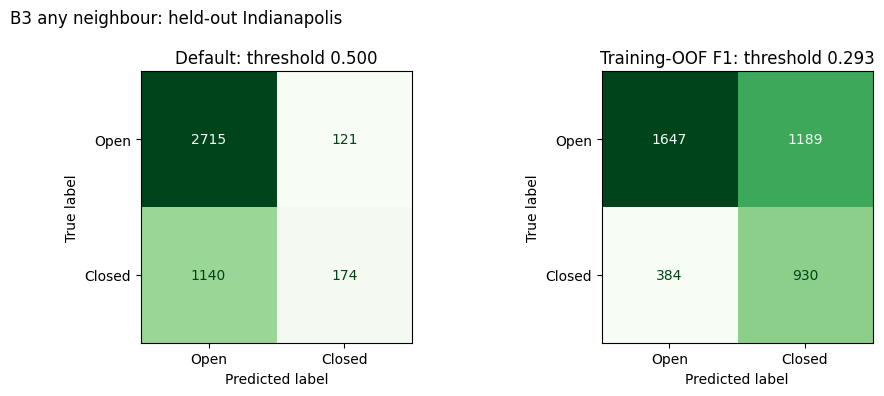

,Threshold,Accuracy,Precision,Recall,F1,FP,FN
Rule,,,,,,,
Default,0.500,69.6%,59.0%,13.2%,21.6%,121,"1,140"
Training-OOF F1,0.293,62.1%,43.9%,70.8%,54.2%,"1,189",384


In [7]:
selected_p = test_predictions[SELECTED_MODEL]
threshold_rows = []
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, label, threshold in zip(axes, ['Default', 'Training-OOF F1'], [0.5, TRAINING_THRESHOLD]):
    values = metrics(test.closed, selected_p, threshold)
    threshold_rows.append({'Rule': label, 'Threshold': threshold, **values})
    cm = confusion_matrix(test.closed, selected_p >= threshold, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Open', 'Closed']).plot(
        ax=ax, cmap='Greens', colorbar=False, values_format='d')
    ax.set_title(f'{label}: threshold {threshold:.3f}')
fig.suptitle(f'{SELECTED_MODEL}: held-out {HOLDOUT_METRO}', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'validation_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()
threshold_results = pd.DataFrame(threshold_rows).set_index('Rule')
display(threshold_results[['Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'FP', 'FN']]
        .style.format({'Threshold': '{:.3f}', **{c: '{:.1%}' for c in ['Accuracy', 'Precision', 'Recall', 'F1']},
                       'FP': '{:,}', 'FN': '{:,}'}))

### Predicted and observed proportions

Group test predictions into ten bins. Compare each bin's mean prediction with its actual closed share; the diagonal shows agreement. This is a descriptive check; no probability-calibration model is fitted.

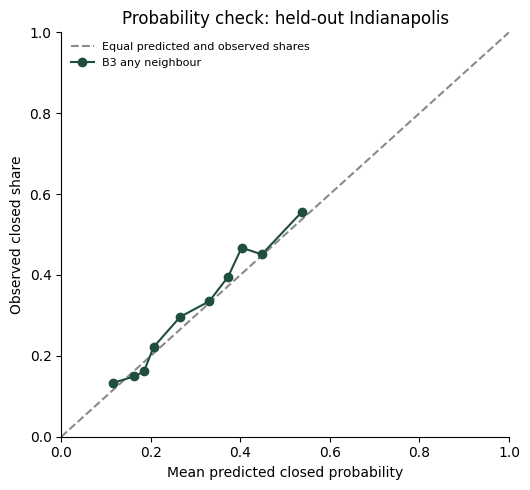

,n,predicted_share,observed_share
bin,,,
1,421,11.5%,13.3%
2,409,16.3%,14.9%
3,415,18.5%,16.1%
4,415,20.6%,22.2%
5,415,26.6%,29.6%
6,415,33.1%,33.5%
7,415,37.2%,39.5%
8,415,40.3%,46.7%
9,417,44.8%,45.1%


Mean prediction 30.3%; observed closed share 31.7%.


In [8]:
bins = pd.qcut(selected_p, 10, labels=False, duplicates='drop')
probability_check = (pd.DataFrame({'bin': bins, 'predicted': selected_p, 'closed': test.closed.to_numpy()})
                     .groupby('bin').agg(n=('closed', 'size'), predicted_share=('predicted', 'mean'),
                                        observed_share=('closed', 'mean')))
probability_check.index = probability_check.index + 1
fig, ax = plt.subplots(figsize=(5.4, 5))
ax.plot([0, 1], [0, 1], linestyle='--', color=GREY, label='Equal predicted and observed shares')
ax.plot(probability_check.predicted_share, probability_check.observed_share, 'o-', color=GREEN,
        label=SELECTED_MODEL)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted closed probability',
       ylabel='Observed closed share', title=f'Probability check: held-out {HOLDOUT_METRO}')
ax.legend(frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'validation_probability_check.png', dpi=180, bbox_inches='tight')
plt.show()
display(probability_check.style.format({'n': '{:,}', 'predicted_share': '{:.1%}', 'observed_share': '{:.1%}'}))
print(f'Mean prediction {selected_p.mean():.1%}; observed closed share {test.closed.mean():.1%}.')

## Step 5 — Bootstrap interval

Resample 2 km spatial cells 1,000 times, keeping nearby restaurants together. Use the same resampled rows for both models. The selected model's 95% AUC interval is **0.672–0.704**. This interval is conditional on the fitted model and Indianapolis; dependence across cells can remain.

In [9]:
reference_latitude = float(test.latitude.mean())
north = test.latitude.to_numpy() * 111.0
east = test.longitude.to_numpy() * 111.0 * np.cos(np.radians(reference_latitude))
cell_keys = list(zip(np.floor(north / BOOTSTRAP_GRID_KM).astype(int),
                     np.floor(east / BOOTSTRAP_GRID_KM).astype(int)))
cell_codes, cell_labels = pd.factorize(pd.MultiIndex.from_tuples(cell_keys))
cell_members = [np.flatnonzero(cell_codes == k) for k in range(len(cell_labels))]
assert len(cell_members) >= 20
rng = np.random.default_rng(SEED)
y_test = test.closed.to_numpy()
bootstrap_rows = []
for _ in range(N_BOOTSTRAP):
    sampled_cells = rng.integers(0, len(cell_members), size=len(cell_members))
    idx = np.concatenate([cell_members[k] for k in sampled_cells])
    if np.unique(y_test[idx]).size != 2:
        continue
    auc = roc_auc_score(y_test[idx], selected_p[idx])
    concept_auc = roc_auc_score(y_test[idx], test_predictions[CONCEPT][idx])
    bootstrap_rows.append({'AUC': auc, 'AUC gain over concept': auc - concept_auc})
bootstrap_samples = pd.DataFrame(bootstrap_rows)
assert len(bootstrap_samples) >= 0.95 * N_BOOTSTRAP
bootstrap_ci = pd.DataFrame({
    'Estimate': [roc_auc_score(y_test, selected_p),
                 roc_auc_score(y_test, selected_p) - roc_auc_score(y_test, test_predictions[CONCEPT])],
    '95% low': bootstrap_samples.quantile(0.025).to_numpy(),
    '95% high': bootstrap_samples.quantile(0.975).to_numpy()
}, index=['AUC', 'AUC gain over concept'])
display(bootstrap_ci.style.format('{:.4f}'))
print(f'{len(cell_members):,} spatial cells; {len(bootstrap_samples):,} valid bootstrap replicates.')

,Estimate,95% low,95% high
AUC,0.6872,0.6719,0.7041
AUC gain over concept,0.0163,0.0065,0.0252


288 spatial cells; 1,000 valid bootstrap replicates.


## Step 6 — Other metros

Leave out each metro in turn and refit both B3 versions. Mean AUC is **0.672**, ranging from **0.614 to 0.710**. Performance varies by city; these checks do not change the selected model.

,Metro_mean_AUC,Metro_SD_AUC,Lowest_metro_AUC,Highest_metro_AUC
Model,,,,
B3 any neighbour,0.6722,0.0272,0.6143,0.7097
B3 share,0.6710,0.0270,0.6128,0.7080


Model,n,B3 any neighbour,B3 share
metro,,,
Philadelphia,"16,944",0.657,0.656
Tampa,"8,732",0.681,0.680
St. Louis,"5,232",0.690,0.687
Nashville,"4,353",0.670,0.671
Indianapolis,"4,150",0.687,0.687
New Orleans,"3,640",0.640,0.638
Tucson,"2,672",0.698,0.695
Edmonton,"2,410",0.669,0.667
Reno,"1,673",0.710,0.708


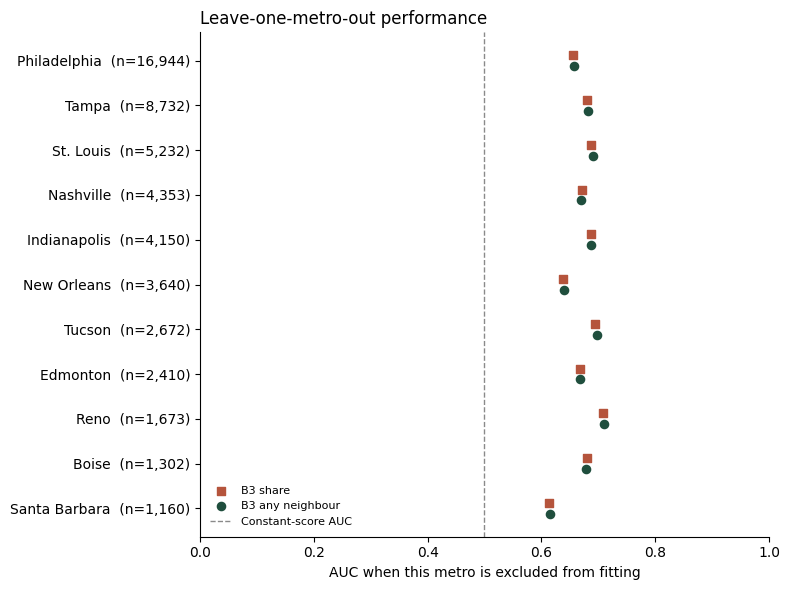

In [10]:
lomo_rows = []
for metro in metro_counts.index:
    fit_data = df.loc[df.metro != metro].copy()
    val_data = df.loc[df.metro == metro].copy()
    assert set(fit_data.metro).isdisjoint(val_data.metro)
    for name in [MAIN, ALTERNATIVE]:
        if metro == HOLDOUT_METRO:
            probabilities = test_predictions[name]
        else:
            _, probabilities = fit_predict(name, fit_data, val_data)
        lomo_rows.append({'Metro': metro, 'Model': name, 'Closed share': val_data.closed.mean(),
                          **metrics(val_data.closed, probabilities)})
lomo = pd.DataFrame(lomo_rows)
lomo_summary = lomo.groupby('Model').agg(Metro_mean_AUC=('AUC', 'mean'),
                                       Metro_SD_AUC=('AUC', 'std'),
                                       Lowest_metro_AUC=('AUC', 'min'), Highest_metro_AUC=('AUC', 'max'))
display(lomo_summary.style.format('{:.4f}'))
lomo_table = lomo.pivot(index='Metro', columns='Model', values='AUC').reindex(metro_counts.index)
lomo_table.insert(0, 'n', metro_counts)
display(lomo_table.style.format({'n': '{:,}', MAIN: '{:.3f}', ALTERNATIVE: '{:.3f}'}))

fig, ax = plt.subplots(figsize=(8, 6))
y_positions = np.arange(len(metro_counts))
for name, offset, color, marker in [(MAIN, -0.12, RUST, 's'), (ALTERNATIVE, 0.12, GREEN, 'o')]:
    values = lomo.set_index(['Metro', 'Model']).loc[(list(metro_counts.index), name), 'AUC'].to_numpy()
    ax.scatter(values, y_positions + offset, color=color, marker=marker, label=name, s=35)
ax.axvline(0.5, color=GREY, linestyle='--', linewidth=1, label='Constant-score AUC')
ax.set_yticks(y_positions, [f'{m}  (n={metro_counts[m]:,})' for m in metro_counts.index])
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_xlabel('AUC when this metro is excluded from fitting')
ax.set_title('Leave-one-metro-out performance', loc='left')
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'validation_leave_one_metro_out.png', dpi=180, bbox_inches='tight')
plt.show()

## Step 7 — Robustness checks

Repeat with 250 m/1 km neighbourhoods and chain cutoffs of 3/10 locations. Recompute all radius-dependent inputs. The known-price-only check uses a different sample. These checks do not select a replacement model.

We also compare independent/chain restaurants and known/missing prices. Independent-restaurant AUC is **0.627**, which limits usefulness for individual founders.

In [11]:
radius_data = df.copy()
coords = np.radians(radius_data[['latitude', 'longitude']].to_numpy())
tree = BallTree(coords, metric='haversine')
prices = radius_data.price_num.to_numpy()
for radius in [250, 1000]:
    neighbour_indices = tree.query_radius(coords, r=radius / 6_371_000)
    means = []
    for i, indices in enumerate(neighbour_indices):
        nearby_prices = prices[indices[indices != i]]
        nearby_prices = nearby_prices[np.isfinite(nearby_prices)]
        means.append(nearby_prices.mean() if len(nearby_prices) else np.nan)
    gap = prices - np.asarray(means)
    radius_data[f'price_gap_missing_{radius}m'] = (~np.isfinite(gap)).astype(int)
    radius_data[f'abs_price_gap_{radius}m'] = np.abs(np.nan_to_num(gap, nan=0.0))

sensitivity_rows = []
variants = [('Main: 500 m, chain 5+', 500, 'is_chain', False),
            ('Radius 250 m', 250, 'is_chain', False),
            ('Radius 1 km', 1000, 'is_chain', False),
            ('Chain cutoff 3+', 500, 'is_chain_3', False),
            ('Chain cutoff 10+', 500, 'is_chain_10', False),
            ('Known price only (different population)', 500, 'is_chain', True)]
for label, radius, chain_column, known_price_only in variants:
    population = radius_data.loc[radius_data.price_tier != 'Missing'] if known_price_only else radius_data
    fit_data = population.loc[population.metro != HOLDOUT_METRO]
    val_data = population.loc[population.metro == HOLDOUT_METRO]
    if label.startswith('Main:'):
        result, probabilities = fitted_models[SELECTED_MODEL], selected_p
    else:
        result, probabilities = fit_predict(SELECTED_MODEL, fit_data, val_data, radius, chain_column)
    sensitivity_rows.append({'Check': label, **metrics(val_data.closed, probabilities),
                             'Density OR: double (1+count)': 2**result.params[f'log_n_rest_{radius}m'],
                             'Chain OR': np.exp(result.params[chain_column])})
sensitivity = pd.DataFrame(sensitivity_rows).set_index('Check')
display(sensitivity[['n', 'AUC', 'AP', 'Probability MSE', 'Density OR: double (1+count)', 'Chain OR']]
        .style.format({'n': '{:,}', **{c: '{:.3f}' for c in ['AUC', 'AP', 'Probability MSE',
                                                           'Density OR: double (1+count)', 'Chain OR']}}))

,n,AUC,AP,Probability MSE,Density OR: double (1+count),Chain OR
Check,,,,,,
"Main: 500 m, chain 5+","4,150",0.687,0.485,0.197,1.119,0.360
Radius 250 m,"4,150",0.694,0.489,0.195,1.132,0.362
Radius 1 km,"4,150",0.682,0.478,0.198,1.124,0.365
Chain cutoff 3+,"4,150",0.683,0.479,0.198,1.124,0.455
Chain cutoff 10+,"4,150",0.694,0.487,0.195,1.116,0.297
Known price only (different population),"3,603",0.688,0.495,0.200,1.124,0.355


In [12]:
subgroup_rows = []
for label, mask in [('Independent', test.is_chain == 0), ('Chain', test.is_chain == 1),
                    ('Known price', test.price_tier != 'Missing'), ('Missing price', test.price_tier == 'Missing')]:
    subgroup_rows.append({'Group': label, 'Closed share': test.loc[mask, 'closed'].mean(),
                          **metrics(test.loc[mask, 'closed'], selected_p[mask.to_numpy()])})
subgroups = pd.DataFrame(subgroup_rows).set_index('Group')
display(subgroups[['n', 'Closed share', 'AUC', 'AP', 'Precision', 'Recall']]
        .style.format({'n': '{:,}', 'Closed share': '{:.1%}', 'AUC': '{:.3f}', 'AP': '{:.3f}',
                       'Precision': '{:.1%}', 'Recall': '{:.1%}'}))
print('Independent/chain and known/missing price are two separate partitions; do not add all four rows.')

,n,Closed share,AUC,AP,Precision,Recall
Group,,,,,,
Independent,"2,671",39.6%,0.627,0.513,59.0%,16.4%
Chain,"1,479",17.3%,0.619,0.265,0.0%,0.0%
Known price,"3,603",33.0%,0.688,0.496,59.0%,14.6%
Missing price,547,22.9%,0.621,0.339,0.0%,0.0%


Independent/chain and known/missing price are two separate partitions; do not add all four rows.


### Open-neighbour counts

Reproduce notebook 01's descriptive comparison. Open-neighbour counts depend on neighbours' status, so they are not used as model predictors.

In [13]:
quintiles = {}
for name, col in [('All listings', 'n_rest_500m'), ('Currently open listings', 'n_open_rest_500m')]:
    q = pd.qcut(df[col].rank(method='first'), 5, labels=['Q1 fewest', 'Q2', 'Q3', 'Q4', 'Q5 most'])
    quintiles[name] = df.groupby(q, observed=True).closed.mean()
descriptive_density = pd.DataFrame(quintiles)
display(descriptive_density.style.format('{:.1%}'))

,All listings,Currently open listings
Q1 fewest,25.0%,26.0%
Q2,28.6%,30.4%
Q3,31.3%,30.9%
Q4,35.6%,34.0%
Q5 most,44.8%,44.0%


## Step 8 — Save outputs

Save tables to `outputs/` and figures to `reports/figures/`. Yelp data and restaurant-level predictions stay local.

In [14]:
tables = {'validation_metrics': test_results, 'validation_cv_folds': cv_folds,
          'validation_cv_summary': cv_summary, 'validation_thresholds': threshold_results,
          'validation_probability_bins': probability_check, 'validation_bootstrap_ci': bootstrap_ci,
          'validation_leave_one_metro_out': lomo, 'validation_robustness': sensitivity,
          'validation_subgroups': subgroups, 'validation_density_descriptive': descriptive_density}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f'{name}.csv')
np.savez_compressed(OUTPUT_DIR / 'validation_test_predictions.npz', y=test.closed.to_numpy(),
                    selected=selected_p, concept=test_predictions[CONCEPT],
                    latitude=test.latitude.to_numpy(), longitude=test.longitude.to_numpy())
np.savez_compressed(OUTPUT_DIR / 'validation_oof_predictions.npz', y=train.closed.to_numpy(),
                    selected=oof[SELECTED_MODEL])

summary = {'holdout': HOLDOUT_METRO, 'holdout_rule': 'Closest to 4000 restaurants, excluding the largest metro; counts only.',
           'n': len(df), 'train_n': len(train), 'test_n': len(test), 'test_closed': int(test.closed.sum()),
           'train_closed_share': float(train.closed.mean()), 'test_closed_share': float(test.closed.mean()),
           'selected_model': SELECTED_MODEL, 'training_threshold': TRAINING_THRESHOLD,
           'cv': cv_summary.reset_index().to_dict('records'), 'test': test_results.reset_index().to_dict('records'),
           'thresholds': threshold_results.reset_index().to_dict('records'),
           'bootstrap': bootstrap_ci.reset_index(names='Metric').to_dict('records'),
           'bootstrap_cells': len(cell_members), 'bootstrap_replicates': len(bootstrap_samples),
           'lomo_summary': lomo_summary.reset_index().to_dict('records'),
           'lomo': lomo.to_dict('records'), 'sensitivity': sensitivity.reset_index().to_dict('records'),
           'subgroups': subgroups.reset_index().to_dict('records'),
           'mean_prediction': float(selected_p.mean()),
           'data_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
           'python': platform.python_version(),
           'source_note': 'Features from notebook 01; fixed B3 share and yes/no specifications from notebook 02. All model fits exclude their evaluation rows.'}
(OUTPUT_DIR / 'validation_summary.json').write_text(json.dumps(summary, indent=2))
print(f'Saved {len(tables)} aggregate tables, the validation summary, and four figures.')

Saved 10 aggregate tables, the validation summary, and four figures.


## Summary

Location and price-position variables improve AUC over concept alone by **0.016** (conditional bootstrap interval **0.007–0.025**). The two B3 versions and the alternative feature definitions give similar results.

The default cutoff misses most closed restaurants. A lower cutoff finds more closures but also flags more open restaurants. Independent-restaurant performance is weaker than overall performance.

These results support modest ranking of snapshot closure status. Without opening/closure dates and historical features, they do not establish future closure risk. Earlier full-sample exploration also limits how conclusive the regional tests can be.

Methods: team notebooks 01–02; [grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data); [validation with structured data](https://doi.org/10.1111/ecog.02881).